# Modelling the spread of an epidemic: SIR models

**Seong Cho** · ACME Volume 4, Lab 4

**Lab objective:** model the spread of an epidemic through a large population with the SIR model and its variations (SIS, SIR with births and deaths, SIRS), and formulate a seasonal SEIR model for measles as a boundary value problem.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.integrate import solve_bvp

## The SIR Model

The SIR model follows a population through three phases of a disease: **susceptible**, **infectious**, and **removed** (those who have died, or have recovered and are now immune). Individuals flow $S \to I \to R$. Over a short outbreak the total population is fixed, so $S'(t) + I'(t) + R'(t) = 0$, and with $S + I + R = 1$ each variable is a fraction of the population.

Let $\beta$ be the average number of contacts per day that could spread the disease. A fraction $S(t)$ of those contacts are with susceptible people, so one infectious individual infects on average $\beta S(t)$ others per day; with total population $N$, $\frac{d}{dt}(S(t)N) = -\beta S(t)(I(t)N)$. A fixed proportion $\gamma$ of the infectious group recovers each day, where $\gamma$ is the reciprocal of the average time spent infectious. Since the derivatives sum to 0,

$$\frac{dS}{dt} = -\beta IS, \qquad \frac{dI}{dt} = \beta IS - \gamma I, \qquad \frac{dR}{dt} = \gamma I.$$

## Problem 1: A basic SIR model

> **Problem 1.** Solve the IVP
>
> $$\frac{dS}{dt} = -\frac{1}{2}IS, \qquad \frac{dI}{dt} = \frac{1}{2}IS - \frac{1}{4}I, \qquad \frac{dR}{dt} = \frac{1}{4}I,$$
>
> $$S(0) = 1 - 6.25\cdot10^{-7}, \qquad I(0) = 6.25\cdot10^{-7}, \qquad R(0) = 0,$$
>
> on the interval $[0, 100]$, and plot your results.

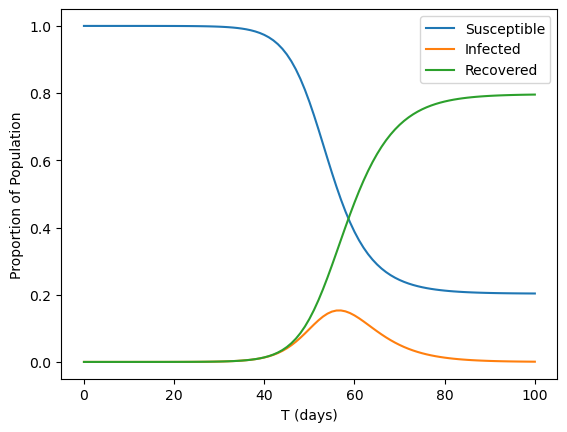

In [2]:
def prob1(y, t):
    dSdt = -1/2 * y[1]*y[0]
    dIdt = 1/2 * y[1]*y[0] - 1/4 * y[1]
    dRdt = 1/4 * y[1]
    return dSdt, dIdt, dRdt

t = np.linspace(0, 100, 101)
y0 = [1 - 6.25e-7, 6.25e-7, 0]
sol = odeint(prob1, y0, t)
plt.plot(t, sol[:,0], label="Susceptible")
plt.plot(t, sol[:,1], label="Infected")
plt.plot(t, sol[:,2], label="Recovered")
plt.xlabel("T (days)")
plt.ylabel("Proportion of Population")
plt.legend()
plt.show()

## Problem 2: A fast-spreading disease

> **Problem 2.** Suppose that, in a city of approximately three million, five have recently entered the city carrying a certain disease. (Suppose they have just entered the infectious state.) Each of those individuals has a contact each day that could spread the disease, and an average of three days is spent in the infectious state. Find the solution of the corresponding SIR equations for the next fifty days and plot your results.
>
> At the peak of the infection, how many in the city will still be able to work (Assume for simplicity that those who are in the infectious state either cannot go to work or are unproductive, etc.) Print your result.

Here $\beta = 1$, $\gamma = 1/3$ and $I(0) = 5/(3\times10^6) \approx 1.67\times10^{-6}$.

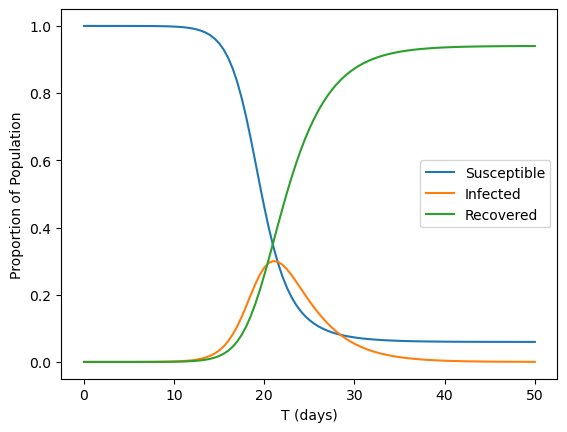

Number of people who can still work: 2099049


In [3]:
def prob2(y, t):
    dSdt = -1 * y[1]*y[0]
    dIdt = 1 * y[1]*y[0] - 1/3 * y[1]
    dRdt = 1/3 * y[1]
    return dSdt, dIdt, dRdt

t = np.linspace(0, 50, 101)
y0 = [1 - 1.67e-6, 1.67e-6, 0]
sol = odeint(prob2, y0, t)
plt.plot(t, sol[:,0], label="Susceptible")
plt.plot(t, sol[:,1], label="Infected")
plt.plot(t, sol[:,2], label="Recovered")
plt.xlabel("T (days)")
plt.ylabel("Proportion of Population")
plt.legend()
plt.show()

w = max(sol[:,1])
num_ppl = (1 - w) * 3e6
print("Number of people who can still work: {}".format(int(num_ppl)))

## Problem 3: A slower disease

> **Problem 3.** Suppose that, in a city of approximately three million, five have recently entered the city carrying a certain disease. (Suppose they have just entered the infectious state.) Each of those individuals will make three contacts every ten days that could spread the disease, and an average of four days is spent in the infectious state. Find the solution of the corresponding SIR equations and plot your results.

Here $\beta = 3/10$ and $\gamma = 1/4$.

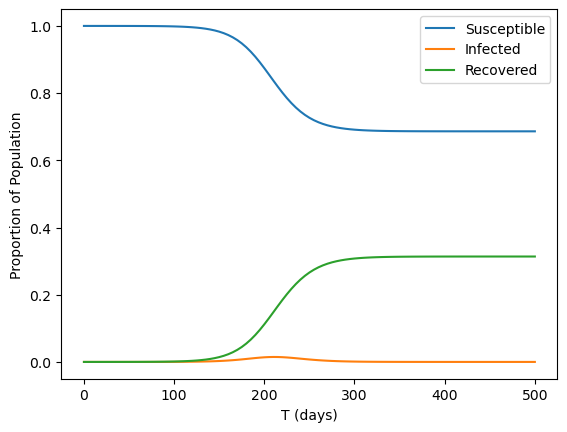

In [4]:
def prob3(y, t):
    dSdt = -3/10 * y[1]*y[0]
    dIdt = 3/10 * y[1]*y[0] - 1/4 * y[1]
    dRdt = 1/4 * y[1]
    return dSdt, dIdt, dRdt

t = np.linspace(0, 500, 101)
y0 = [1 - 1.67e-6, 1.67e-6, 0]
sol = odeint(prob3, y0, t)
plt.plot(t, sol[:,0], label="Susceptible")
plt.plot(t, sol[:,1], label="Infected")
plt.plot(t, sol[:,2], label="Recovered")
plt.xlabel("T (days)")
plt.ylabel("Proportion of Population")
plt.legend()
plt.show()

## Variations on the SIR Model

**SIS models** describe diseases that give no lasting immunity, so recovered individuals become susceptible again. There are only two compartments:

$$\frac{dS}{dt} = -\beta IS + \gamma I, \qquad \frac{dI}{dt} = \beta IS - \gamma I.$$

Adding a death rate $\mu$ and an equal birth rate to the SIR model, with every newborn susceptible, gives

$$\frac{dS}{dt} = \mu(1 - S) - \beta IS, \qquad \frac{dI}{dt} = \beta IS - (\gamma + \mu)I, \qquad \frac{dR}{dt} = \gamma I - \mu R.$$

**SIRS models** also let recovered individuals rejoin the susceptible class at rate $f$:

$$\frac{dS}{dt} = fR + \mu(1 - S) - \beta IS, \qquad \frac{dI}{dt} = \beta IS - (\gamma + \mu)I, \qquad \frac{dR}{dt} = -fR + \gamma I - \mu R.$$

## Problem 4: An SIRS model of the flu

> **Problem 4.** In the world there are 7 billion people. Influenza, or the flu, is one of those viruses that everyone can be susceptible to, even after recovering from their last sickness. The flu virus is able to change in order to evade our immune system and we become susceptible once more (although technically it is now a different strain). Suppose the virus originates with 1000 people in Texas after Hurricane Harvey flooded Houston and stagnant water allowed the virus to proliferate. According to WebMD (trustworthy source, right?), once you get the virus you are contagious up to a week, and kids up to 2 weeks. For this lab, suppose you are contagious for 10 days before recovering. Also suppose that on average someone makes one contact every two days that could spread the flu. Since we can catch a new strain of the flu, suppose that a recovered individual becomes susceptible again with probability $f = 1/50$. The flu is also known to be deadly, killing hundreds of thousands every year on top of the normal death rate. To assure a steady population, let the birth rate balance out the death rate, and in particular let $\mu = .0001$.
>
> Using the SIRS model above, plot the proportion of population that is Susceptible, Infected, and Recovered over a year span (365 days).

Here $\beta = 1/2$, $\gamma = 1/10$ and $I(0) = 1000/(7\times10^9) \approx 1.43\times10^{-7}$.

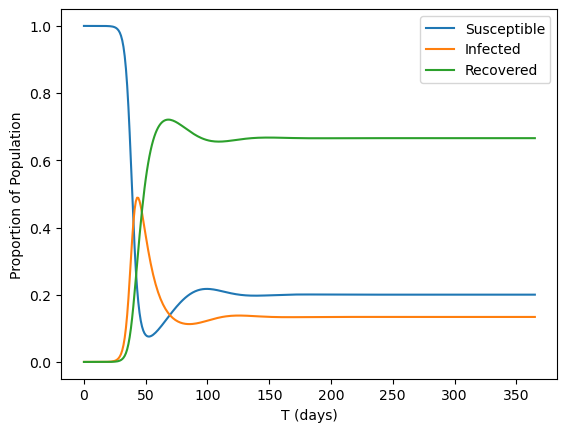

In [5]:
def prob4(y, t):
    dSdt = 1/50 * y[2] + .0001*(1 - y[0]) - 1/2 * y[0]*y[1]
    dIdt = 1/2 * y[0]*y[1] - (1/10 + .0001)*y[1]
    dRdt = -1/50 * y[2] + 1/10 * y[1] - .0001*y[2]
    return dSdt, dIdt, dRdt

t = np.linspace(0, 365, 366)
y0 = [1 - 1.43e-7, 1.43e-7, 0]
sol = odeint(prob4, y0, t)
plt.plot(t, sol[:,0], label="Susceptible")
plt.plot(t, sol[:,1], label="Infected")
plt.plot(t, sol[:,2], label="Recovered")
plt.xlabel("T (days)")
plt.ylabel("Proportion of Population")
plt.legend()
plt.show()

## Boundary Value Problem

An **SEIR** model of measles (Ascher, Mattheij and Russell) adds an *exposed* (latency) compartment and makes the contact rate seasonal, i.e. periodic, so the yearly occurrence of measles becomes a boundary value problem:

$$\begin{bmatrix} S \\ E \\ I \end{bmatrix}' = \begin{bmatrix} \mu - \beta(t)SI \\ \beta(t)SI - E/\lambda \\ E/\lambda - I/\eta \end{bmatrix}, \tag{4.1}$$

$$S(0) = S(1), \tag{4.2}$$
$$E(0) = E(1), \tag{4.3}$$
$$I(0) = I(1). \tag{4.4}$$

Here $\mu$ is the birth rate, $\lambda$ the latency period of measles, and $\eta$ the infectious period before an individual moves to the recovered class. Recovered individuals stay immune, so $R(t)$ is left out of the system.

SciPy's `solve_bvp` is a full-featured BVP solver. The spec's example solves

$$\varepsilon y'' + yy' - y = 0, \qquad y(-1) = 1, \quad y(1) = -1/3, \quad \varepsilon = .1 \tag{4.5}$$

as a first-order system in $(y, y')$; `bcs()` returns the residuals of the boundary conditions, which are 0 when they are met exactly:

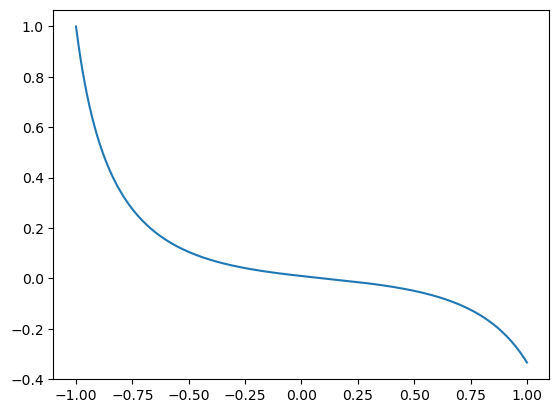

In [6]:
epsilon, lbc, rbc = .1, 1, - 1/3

# The ode function takes the independent variable first
# It has return shape (n,)
def ode(x , y):
    return np.array([y[1] , (1/epsilon) * (y[0] - y[0] * y[1])])

# One boundary condition on either side; each evaluates to 0 when satisfied.
# The return shape of bcs() is (n,)
def bcs(ya, yb):
    BCa = np.array([ya[0] - lbc])    # 1 Boundary condition on the left
    BCb = np.array([yb[0] - rbc])    # 1 Boundary condition on the right
    return np.hstack([BCa, BCb])

# The independent variable has size (m,); the y input has shape (n,m) and is the initial guess
X = np.linspace(-1, 1, 200)
y = np.array([-1/3, -4/3]).reshape((-1,1))*np.ones((2, len(X)))
solution = solve_bvp(ode, bcs, X, y)

# We are interested in only y, not y', which is found in the first row of sol.
y_plot = solution.sol(X)[0]
plt.plot(X, y_plot)
plt.show()

## Problem 5: A seasonal SEIR model of measles

> **Problem 5.** Consider (4.1). Let the periodic function for our measles case be $\beta(t) = \beta_0(1 + \beta_1\cos 2\pi t)$. Use parameters $\beta_1 = 1$, $\beta_0 = 1575$, $\eta = 0.01$, $\lambda = .0279$, and $\mu = .02$. Note: in this case, time is measured in years, so run the solution over the interval $[0, 1]$ to show a one-year cycle. The boundary conditions are really just saying that the year will begin and end in the same state.
>
> `solve_bvp` requires separated boundary conditions. In other words, each equation in the set of boundary conditions can only include values at one end of the interval. To deal with this, let $C = [C_1, C_2, C_3]$, and add the equation
>
> $$C' = 0$$
>
> to the system of ODEs given above (for a total of 6 equations). Then the boundary conditions can be separated using the following trick:
>
> $$\begin{bmatrix} C_1(0) \\ C_2(0) \\ C_3(0) \end{bmatrix} = \begin{bmatrix} S(0) \\ E(0) \\ I(0) \end{bmatrix}, \qquad \begin{bmatrix} C_1(1) \\ C_2(1) \\ C_3(1) \end{bmatrix} = \begin{bmatrix} S(1) \\ E(1) \\ I(1) \end{bmatrix}.$$
>
> Now $C_1, C_2, C_3$ become the 4th, 5th, and 6th rows of your solution matrix, so the 3 boundary conditions for the left are obtained by subtracting the last three entries of $y(0)$ from the first three entries, giving you `ya[0:3] - ya[3:]`. Similarly, your right boundary conditions will look like `yb[0:3] - yb[3:]`.
>
> When you code your boundary conditions, note that `solve_bvp` changes the initial conditions to force all the entries in the return of `bcs()` to be zero. You can use the initial conditions from Fig. 4.4 as your initial guess (which will be an array of 6 elements). Remember that the initial infected proportion is small, not 0.

*Not completed.*